# RetinaNet results: anchor scales and frame sampling

We compare four independently initialized RetinaNet ResNet-50 FPN V2 experiments.
All four runs completed five epochs with seed 2026, batch size 2, resize 640/1024,
SGD with learning rate 0.0025, Focal Loss and GIoU regression. Smaller anchors halve
the standard sizes while keeping the aspect ratios and number of anchors unchanged.
The model and anchor-size rationale are described in `02_retinanet.ipynb`.

We evaluate all 2,846 official validation frames after every epoch with canonical
COCO maxDets=100. AP values below use the 0 to 1 scale. The main comparison uses
**epoch 5** for every run; we show the separately selected best checkpoints as well.

In [1]:
import json
import sys
from io import BytesIO
from pathlib import Path

import plotly.io
import polars as pl
from decouple import config
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from PIL import Image

ROOT = Path.cwd() if Path("pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from hm2.experiment_names import EXPERIMENTS, experiment_label
from hm2.retinanet_analysis import summarize_batch

BATCH_ID = "retinanet_stride5_full_5epochs_seed2026"
SAVED_RESULTS = ROOT / "results/retinanet" / BATCH_ID
batch_dir = Path(config("RETINANET_BATCH_DIR", default=str(SAVED_RESULTS))).expanduser()
OUTPUT_DIRECTORY = ROOT / "runs/retinanet_analysis" / BATCH_ID
if not batch_dir.is_dir():
    raise FileNotFoundError(
        "Download and extract the Drive result archive before rerunning. "
        "See the reproduction instructions at the end of this notebook."
    )
EXPERIMENT_LABELS = {name: experiment_label(name) for name in EXPERIMENTS}
pl.Config.set_tbl_cols(12)
pl.Config.set_tbl_rows(32)
pl.Config.set_fmt_str_lengths(90)
summary = summarize_batch(batch_dir, output_dir=OUTPUT_DIRECTORY)
comparison = pl.from_dicts(summary["comparison"], infer_schema_length=None)
validation_records = {
    name: json.loads((batch_dir / name / "metrics.json").read_text()) for name in EXPERIMENTS
}
best_records = {
    name: max(records, key=lambda row: row["metrics"]["map"])
    for name, records in validation_records.items()
}

## 1. Completed training budgets

The stride-five selection contains 4,868 frames from all 56 training clips. Full-data
training uses all 24,201 frames from those clips. Both settings use the same separate
validation split, with no shared training clips. We save the exact frame selections.

Five full-data epochs expose approximately five times as many images and optimizer
updates. This comparison combines data coverage and training budget. AMP skipped a small
number of updates, so successful-update counts differ slightly between anchor settings.
Training time is the sum of end-to-end batch latencies; it excludes setup, validation,
checkpoint transfers, session interruptions and time between sessions.

In [2]:
comparison.select(
    pl.col("experiment_id").replace_strict(EXPERIMENT_LABELS).alias("Experiment"),
    pl.col("status").alias("Status"),
    pl.col("train_frames").alias("Train frames"),
    pl.col("epoch").alias("Epochs"),
    pl.col("global_step").alias("Optimizer updates"),
    pl.col("image_exposures").alias("Image exposures"),
    (pl.col("train_seconds") / 60).round(2).alias("Training batch time (min)"),
    (pl.col("image_exposures") / pl.col("train_seconds")).round(2).alias("Training images/s"),
)

Experiment,Status,Train frames,Epochs,Optimizer updates,Image exposures,Training batch time (min),Training images/s
str,str,i64,i64,i64,i64,f64,f64
"""RetinaNet with standard anchors (every fifth frame)""","""Completed""",4868,5,12165,24340,59.61,6.81
"""RetinaNet with smaller anchors (every fifth frame)""","""Completed""",4868,5,12166,24340,60.04,6.76
"""RetinaNet with standard anchors (full training set)""","""Completed""",24201,5,60484,121005,284.18,7.1
"""RetinaNet with smaller anchors (full training set)""","""Completed""",24201,5,60485,121005,283.14,7.12


## 2. Validation at epoch 5

We compare the final models under the same validation protocol. Validation inference
throughput includes decoding, collation, transfers, model transforms, inference, NMS
and CPU outputs. It excludes COCO evaluation. These timings come from the recorded
sessions and are not a controlled hardware benchmark across sessions.

In [3]:
comparison.select(
    pl.col("experiment_id").replace_strict(EXPERIMENT_LABELS).alias("Experiment"),
    pl.col("map").round(6).alias("mAP"),
    pl.col("ap50").round(6).alias("AP50"),
    pl.col("ap75").round(6).alias("AP75"),
    pl.col("ap_small").round(6).alias("AP small"),
    pl.col("ap_medium").round(6).alias("AP medium"),
    pl.col("ap_large").round(6).alias("AP large"),
    pl.col("fps").round(2).alias("Validation inference frames/s"),
)

Experiment,mAP,AP50,AP75,AP small,AP medium,AP large,Validation inference frames/s
str,f64,f64,f64,f64,f64,f64,f64
"""RetinaNet with standard anchors (every fifth frame)""",0.152786,0.291178,0.14184,0.053135,0.131627,0.316873,8.04
"""RetinaNet with smaller anchors (every fifth frame)""",0.148782,0.316268,0.123687,0.052404,0.130756,0.276468,8.17
"""RetinaNet with standard anchors (full training set)""",0.150543,0.285836,0.138214,0.049999,0.127531,0.320663,15.04
"""RetinaNet with smaller anchors (full training set)""",0.156314,0.324951,0.134056,0.054759,0.142678,0.303211,14.39


## 3. Best checkpoints by validation mAP

We select `best.pt` by the highest full-validation mAP across the five epochs.
This selection is separate from the equal-epoch comparison above. For standard anchors
with full training, the best epoch is 1; for smaller anchors with full training, it is 4.
Both stride-five runs select epoch 5. Prediction overlays below show epoch 5.

In [4]:
pl.from_dicts(
    [
        {
            "Experiment": experiment_label(name),
            "Selected epoch": record["epoch"],
            "mAP": record["metrics"]["map"],
            "AP50": record["metrics"]["ap50"],
            "AP small": record["metrics"]["ap_small"],
            "AP medium": record["metrics"]["ap_medium"],
            "AP large": record["metrics"]["ap_large"],
        }
        for name, record in best_records.items()
    ]
)

Experiment,Selected epoch,mAP,AP50,AP small,AP medium,AP large
str,i64,f64,f64,f64,f64,f64
"""RetinaNet with standard anchors (every fifth frame)""",5,0.152786,0.291178,0.053135,0.131627,0.316873
"""RetinaNet with smaller anchors (every fifth frame)""",5,0.148782,0.316268,0.052404,0.130756,0.276468
"""RetinaNet with standard anchors (full training set)""",1,0.157504,0.299334,0.0525,0.131319,0.327028
"""RetinaNet with smaller anchors (full training set)""",4,0.158831,0.333095,0.058264,0.145968,0.306402


## 4. Anchor tuning and full-data training contrasts

We subtract standard anchors from smaller anchors within each data selection, then
subtract stride-five training from full-data training within each anchor setting.
The table reports epoch-5 differences in percentage points, where 1 point equals
0.01 AP. These are descriptive differences from one seed, not statistical significance.

At epoch 5, smaller anchors increase AP50 in both data selections. With full training,
they increase mAP, AP_small and AP_medium while lowering AP_large. With stride-five
training, mAP and AP_small decrease slightly. Full-data training does not show a uniform
advantage at epoch 5, and its effect cannot be attributed exclusively to frame selection.

In [5]:
contrast_labels = {
    "anchors_stride": "Smaller minus standard anchors, every fifth frame",
    "anchors_full": "Smaller minus standard anchors, full training set",
    "full_minus_stride_baseline": "Full minus every fifth frame, standard anchors",
    "full_minus_stride_tuned": "Full minus every fifth frame, smaller anchors",
}
pl.from_dicts(
    [
        {
            "Contrast": contrast_labels[name],
            "Delta mAP (pp)": values["map"] * 100,
            "Delta AP50 (pp)": values["ap50"] * 100,
            "Delta AP small (pp)": values["ap_small"] * 100,
            "Delta AP medium (pp)": values["ap_medium"] * 100,
            "Delta AP large (pp)": values["ap_large"] * 100,
        }
        for name, values in summary["differences"].items()
    ]
)

Contrast,Delta mAP (pp),Delta AP50 (pp),Delta AP small (pp),Delta AP medium (pp),Delta AP large (pp)
str,f64,f64,f64,f64,f64
"""Smaller minus standard anchors, every fifth frame""",-0.400475,2.509005,-0.073045,-0.08709,-4.040577
"""Smaller minus standard anchors, full training set""",0.577067,3.911453,0.476023,1.514627,-1.745223
"""Full minus every fifth frame, standard anchors""",-0.224341,-0.53423,-0.313631,-0.409529,0.378959
"""Full minus every fifth frame, smaller anchors""",0.753201,0.868218,0.235437,1.192188,2.674313


## 5. Class AP at epoch 5

We retain the eight assignment categories and report the same COCO AP definition
for each class. The plots below show the class comparison alongside aggregate metrics.

In [6]:
class_rows = [
    {
        "Class": class_name,
        "Experiment": experiment_label(row["experiment_id"]),
        "AP": score,
    }
    for row in summary["comparison"]
    for class_name, score in row["per_class_ap"].items()
]
pl.from_dicts(class_rows).pivot(on="Experiment", index="Class", values="AP")

Class,RetinaNet with standard anchors (every fifth frame),RetinaNet with smaller anchors (every fifth frame),RetinaNet with standard anchors (full training set),RetinaNet with smaller anchors (full training set)
str,f64,f64,f64,f64
"""person""",0.203834,0.211988,0.205685,0.215429
"""bicycle""",0.106394,0.133531,0.076764,0.128947
"""car""",0.339475,0.328795,0.331044,0.333632
"""van""",0.164058,0.15207,0.154683,0.170766
"""truck""",0.162982,0.155979,0.147277,0.164201
"""tricycle""",0.140784,0.120347,0.128633,0.134819
"""bus""",0.03764,0.008979,0.086707,0.013251
"""motor""",0.067124,0.078563,0.07355,0.089463


## 6. Validation and training curves

Validation curves contain all five complete validation measurements. Loss curves show
batch means over windows of at most 100 attempts, split at epoch boundaries. The learning
rate is the last value in each window, and the horizontal axis counts successful optimizer
updates. The saved compact curve records retain the number of batches per window.
We regenerate interactive figures from those records without embedding Plotly.js.

In [7]:
chart_paths = {Path(chart).stem: Path(chart).with_suffix(".json") for chart in summary["charts"]}
for name in (
    "metrics",
    "ap_small",
    "per_class",
    "validation_curves",
    "loss",
    "classification",
    "bbox_regression",
    "learning_rate",
    "time",
):
    plotly.io.read_json(chart_paths[name]).show(
        renderer="plotly_mimetype", config={"responsive": False}
    )

## 7. Consistent validation diagnostics

We show the same dense scene, tiny-object scene and missed-GT example for all four
final models. The source selection used metadata and greedy class-aware IoU 0.5 matching
at score ≥ 0.3 in the standard-anchor stride-five run. This is a qualitative diagnostic,
not the COCO evaluator. Ignored regions remain visible, and valid GT inside them is kept.
Notebook previews are resized for compact display; each caption links the original overlay.

**RetinaNet with standard anchors (every fifth frame): Dense scene.** `val/uav0000137_00458_v/0000142`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1swh_as6gmenEaI54nfELpu5PoYbFiwZ7/view)

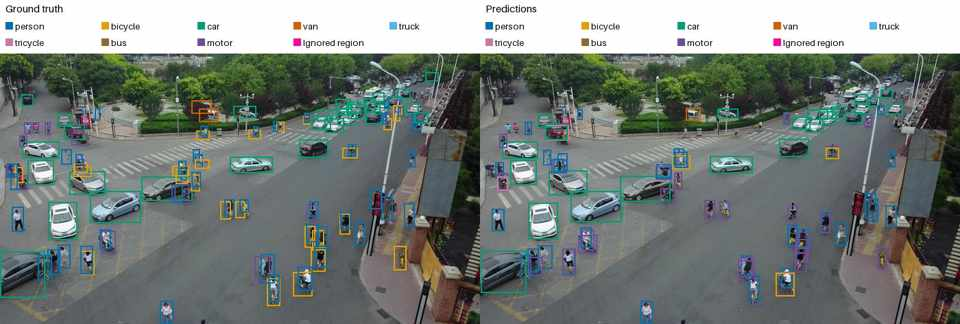

**RetinaNet with smaller anchors (every fifth frame): Dense scene.** `val/uav0000137_00458_v/0000142`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1TDhALjaYcy8k-x0lElBr4i8gOwGeZ7X3/view)

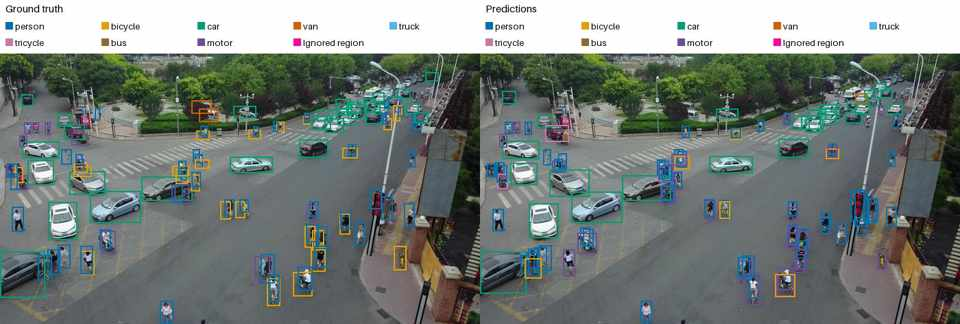

**RetinaNet with standard anchors (full training set): Dense scene.** `val/uav0000137_00458_v/0000142`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/140CjayGhJanVNA7LjurZrCBxlCt3yclB/view)

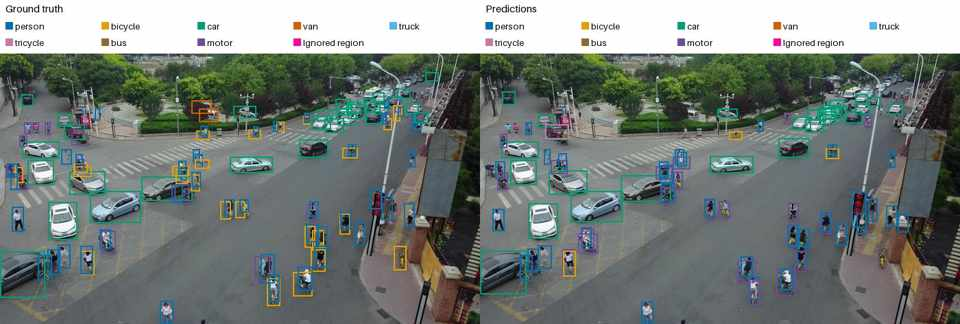

**RetinaNet with smaller anchors (full training set): Dense scene.** `val/uav0000137_00458_v/0000142`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1GukZj1Ai9jbDnVrOQEYwrDuNjAuvWavt/view)

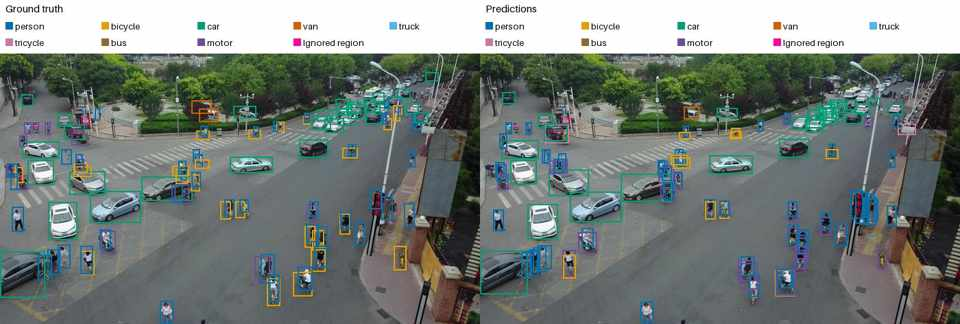

**RetinaNet with standard anchors (every fifth frame): Tiny objects.** `val/uav0000117_02622_v/0000301`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1NXJA-JG9XJADKWtviOfQ-1gw0il-01p9/view)

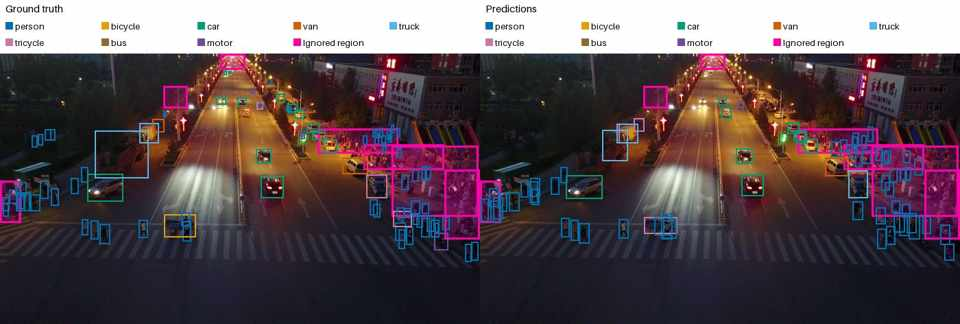

**RetinaNet with smaller anchors (every fifth frame): Tiny objects.** `val/uav0000117_02622_v/0000301`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1unaXPigHDSyKzFU-_-ewioBeYZv5274C/view)

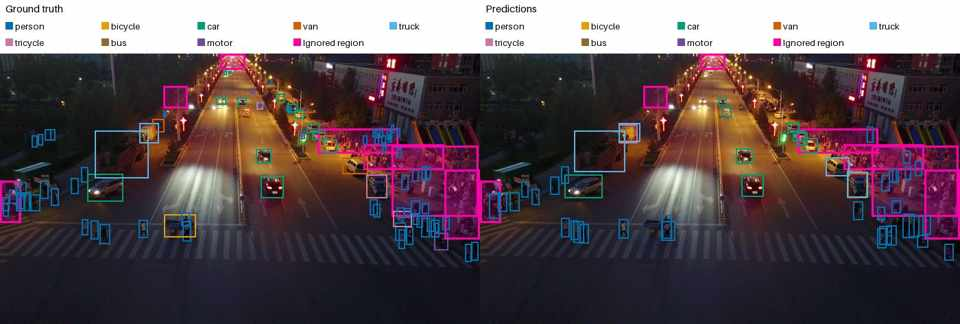

**RetinaNet with standard anchors (full training set): Tiny objects.** `val/uav0000117_02622_v/0000301`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1epHXNcmZ8i7uBUWs8aoCsQYQKW-tMlm8/view)

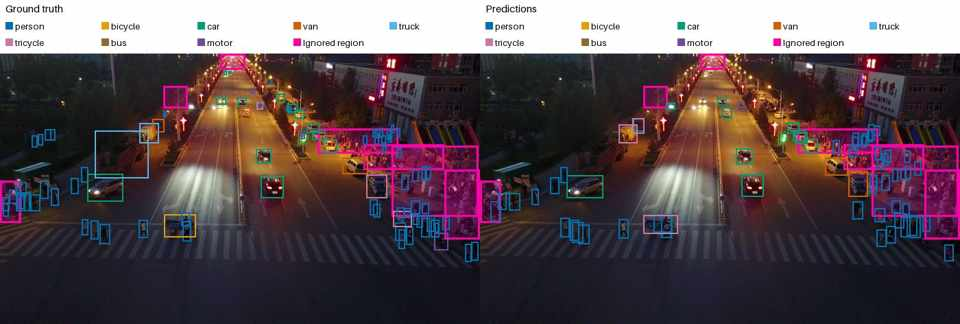

**RetinaNet with smaller anchors (full training set): Tiny objects.** `val/uav0000117_02622_v/0000301`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1aXuqwdRKKif9cd0IpYEzfr0YMK3TkIVN/view)

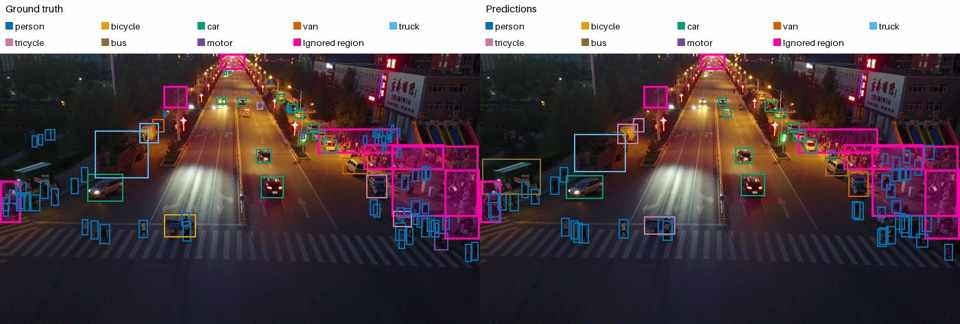

**RetinaNet with standard anchors (every fifth frame): Missed GT in RetinaNet with standard anchors (every fifth frame) at IoU 0.5.** `val/uav0000137_00458_v/0000143`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/10Jq0jRQzwcvpsObMTscS2vHJSKnI-jso/view)

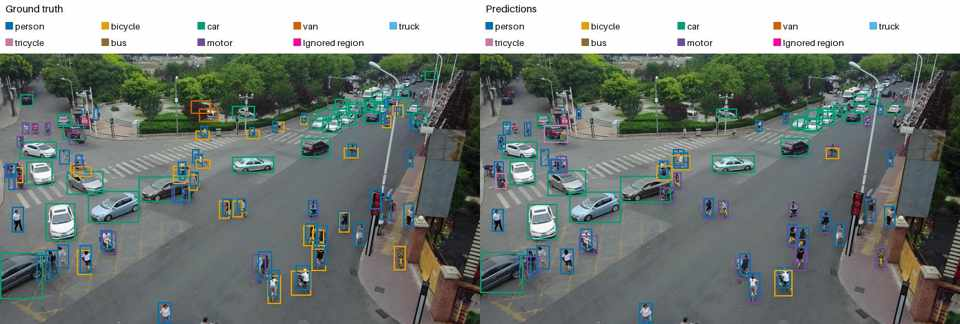

**RetinaNet with smaller anchors (every fifth frame): Missed GT in RetinaNet with standard anchors (every fifth frame) at IoU 0.5.** `val/uav0000137_00458_v/0000143`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1CQ3RvI2F94waXpL8yOoh5uGf_8pdYAKv/view)

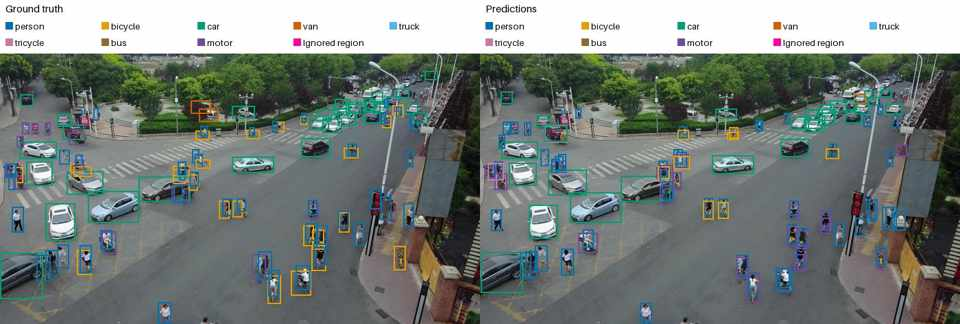

**RetinaNet with standard anchors (full training set): Missed GT in RetinaNet with standard anchors (every fifth frame) at IoU 0.5.** `val/uav0000137_00458_v/0000143`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1l520Y89S0phJsnhhSP3WzBeAYK8c70dW/view)

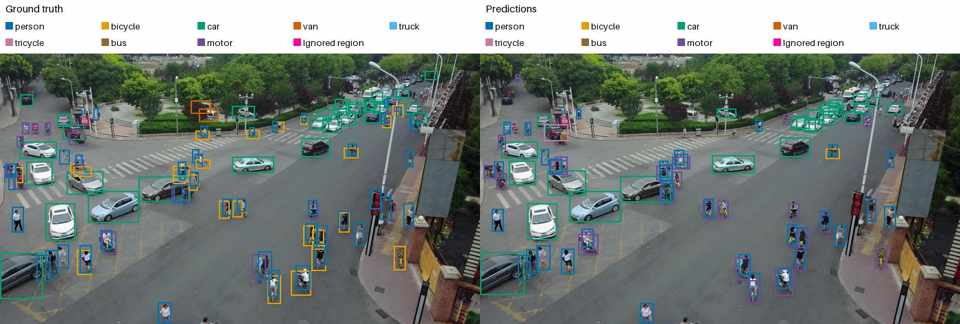

**RetinaNet with smaller anchors (full training set): Missed GT in RetinaNet with standard anchors (every fifth frame) at IoU 0.5.** `val/uav0000137_00458_v/0000143`, epoch 5, score ≥ 0.3. [Original overlay](https://drive.google.com/file/d/1CNDnDBhIvaDWUmJ4srQO2qKS9hU4D2MR/view)

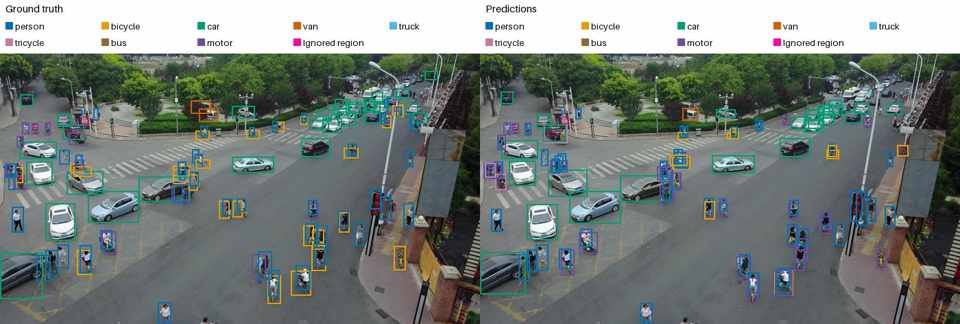

In [8]:
previews = json.loads((batch_dir / "preview_selection.json").read_text())
for preview in previews:
    path = batch_dir / preview["path"]
    original_url = f"https://drive.google.com/file/d/{preview['source_file_id']}/view"
    display(
        Markdown(
            f"**{experiment_label(preview['experiment_id'])}: {preview['reason']}.** "
            f"`{preview['image_key']}`, epoch {preview['epoch']}, score ≥ 0.3. "
            f"[Original overlay]({original_url})"
        )
    )
    with Image.open(path) as image:
        image.thumbnail((960, 400))
        buffer = BytesIO()
        image.save(buffer, format="JPEG", quality=45, optimize=True)
    display(DisplayImage(data=buffer.getvalue()))

## 8. Evaluation boundaries and pending comparison

We retain original category-specific COCO crowd annotations, IoU thresholds 0.50 to 0.95
and maxDets [1, 10, 100]. This does not establish equivalence to the competition's ignore
semantics, which remain unverified. Stock RetinaNet does not suppress ignored-region
negative anchors. Preview score filtering does not change evaluation predictions.

The tuned Faster R-CNN comparison remains **Not run** here. We need the teammate's
measured results under the same protocol before comparing detector families.
CUDA kernels and runtime changes can affect numerical reproducibility. The runtime
records do not capture the exact training source commit, so we do not claim bit-for-bit
reproduction of the original training executions.

## 9. Reproducing this comparison

We preserve the measured records, exact frame selections, compact training curves,
environment information and original validation overlays in the
[Drive result archive](https://drive.google.com/file/d/1e5AybR4U8T-SMt2nJ8XcipM_2ye5COUn/view).
The saved notebook outputs can be reviewed without downloading those files.

To rerun this CPU-only analysis, download `retinanet_completed_results.zip` and extract
it into `results/retinanet/` from the repository root:

```bash
uv run python -m zipfile -e /path/to/retinanet_completed_results.zip results/retinanet
```

The extracted JSON, logs and previews are gitignored input records. They are not needed
after viewing the saved results and can be deleted after rerunning. No persistent cache
is created automatically. Generated tables and plots go to the gitignored
`runs/retinanet_analysis/` directory. Rerunning regenerates the presentation of saved
measurements, not the original COCO evaluation or training.

The archive's `provenance.json` records source generations, file IDs and SHA256 hashes,
including checkpoint references. We export all four validation-selected models on the
complete test split; the CSVs and their metadata are kept in the
[Drive submission batch](https://drive.google.com/drive/folders/1NBGbuvGnWHgeikhZFh5KPa1X1gRfuL-F).
Local CSV paths are documented in [submissions](../submissions/README.md).
